# Lesson 3.1.1 — What Is Machine Learning?
## From Data to Predictions

**Series:** AI & ML — Learn • Build • Grow  
**Module:** 3.1 — ML Fundamentals  
**Main tool:** PyTorch  
**Environment:** Jupyter Notebook, CPU-friendly

In this lesson, we will build a tiny machine-learning model ourselves. We will give it examples of house areas and prices, train a model to learn a relationship, and ask it to predict the price of a new house.

> **The central idea:** instead of writing every answer by hand, we give a learning algorithm examples and let it adjust a model's parameters to find a useful pattern.

### What you will understand by the end

- What data, features, and targets mean in a supervised-learning example.
- What a model is and what its parameters represent.
- How a PyTorch model makes a prediction.
- Why we need a loss function.
- How `loss.backward()` calculates gradients and `optimizer.step()` updates parameters.
- How to use the trained model to predict a new example.

### Scope of this first lesson

We will use one simple linear model so the learning process is visible. We will **not** go deeply into train/validation/test splitting, model evaluation, overfitting, or the mathematics of regression here; those topics have dedicated lessons later in this module and phase.

**Important:** the house data are synthetic teaching data. This model is not a real-estate valuation tool.

## Step 0 — Prepare the environment

Install the packages in a terminal. PyTorch's CPU build is enough; an NVIDIA GPU is not required.

```bash
python -m pip install --upgrade pip
python -m pip install torch numpy pandas matplotlib jupyterlab
```

Start JupyterLab from the `lesson_example` directory, then open this notebook from the `notebooks` folder:

```bash
jupyter lab
```

In [1]:
# Step 0: imports and reproducibility settings
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

# Keep this lesson reproducible when it is run again.
RANDOM_SEED = 42
TORCH_SEED = 7
np.random.seed(RANDOM_SEED)
torch.manual_seed(TORCH_SEED)

# CPU is deliberately used so the notebook runs on ordinary computers.
DEVICE = torch.device("cpu")
torch.set_num_threads(1)

# Resolve the lesson folder whether Jupyter is launched from the project root
# or from the notebooks directory.
WORKING_DIR = Path.cwd()
if WORKING_DIR.name == "notebooks":
    LESSON_DIR = WORKING_DIR.parent
elif (WORKING_DIR / "notebooks").is_dir():
    LESSON_DIR = WORKING_DIR
elif (WORKING_DIR / "lesson_example" / "notebooks").is_dir():
    LESSON_DIR = WORKING_DIR / "lesson_example"
else:
    LESSON_DIR = WORKING_DIR
OUTPUT_DIR = LESSON_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {DEVICE}")

PyTorch version: 2.15.0+cpu
Device: cpu


## Step 1 — Start with a prediction problem

Imagine that we are helping someone estimate a house price. We know the floor area of several houses and their previous sale prices.

**Question:** if a new house has an area of **120 m²**, what price might be reasonable?

We do not want to hard-code a separate answer for every possible area. Instead, we will use examples to teach a model a relationship between area and price.

## Step 2 — Create a small dataset

For a beginner lesson, we will generate our own data so that the notebook is reproducible and does not depend on downloading a dataset.

Each row represents one house:

- `area_m2`: the house area in square metres.
- `price_usd`: the example sale price in US dollars.

The synthetic data are generated around a simple pattern with some random noise. The noise makes the examples more realistic: houses with similar areas do not have exactly identical prices.

In [2]:
# Step 2: create 40 synthetic house examples
rng = np.random.default_rng(RANDOM_SEED)

area_m2 = np.round(rng.uniform(50, 180, size=40), 1)
noise_usd = rng.normal(loc=0, scale=15_000, size=40)

# This rule is used only to create teaching data.
# The model will NOT be given these coefficients during training.
price_usd = np.round(50_000 + 2_500 * area_m2 + noise_usd).astype(int)

houses = pd.DataFrame({
    "area_m2": area_m2,
    "price_usd": price_usd,
})

print(f"Number of examples: {len(houses)}")
display(houses.head(10))

Number of examples: 40


,area_m2,price_usd
0,150.6,437649
1,107.1,325897
2,161.6,444017
3,140.7,405232
4,62.2,207250
5,176.8,495280
6,148.9,435321
7,152.2,433854
8,66.7,226934
9,108.6,322514


## Step 3 — Look at the examples

A table is useful, but a chart can make the relationship easier to notice. Each dot is one house. The horizontal position is its area; the vertical position is its price.

At this stage, we are only observing the data. We have not trained a model yet.

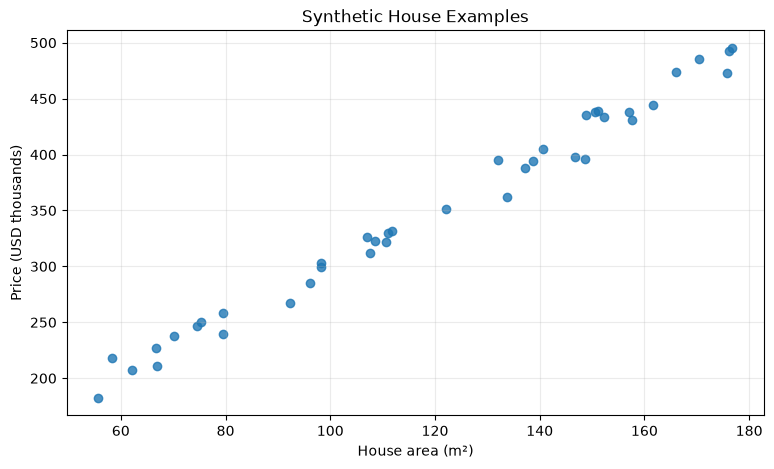

In [3]:
# Step 3: visualize the data before training
plt.figure(figsize=(9, 5))
plt.scatter(houses["area_m2"], houses["price_usd"] / 1_000, alpha=0.8)
plt.title("Synthetic House Examples")
plt.xlabel("House area (m²)")
plt.ylabel("Price (USD thousands)")
plt.grid(alpha=0.25)
plt.show()

## Step 4 — Identify the input and the answer

In this example, the information we give the model is the house area. We call it a **feature** or **input**.

The value we want the model to learn to predict is the house price. We call it the **target**. Because each training example already includes its target price, this is a simple example of **supervised learning**.

For this first lesson, there is one feature and one target:

| Role | Column | Meaning |
|---|---|---|
| Feature / input | `area_m2` | What we give the model |
| Target / label | `price_usd` | The example answer we want it to learn |

In [4]:
# Step 4: separate the feature (X) and target (y)
X_area_m2 = houses[["area_m2"]].to_numpy(dtype=np.float32)
y_price_usd = houses[["price_usd"]].to_numpy(dtype=np.float32)

print("Feature array shape:", X_area_m2.shape)
print("Target array shape:", y_price_usd.shape)
print("First feature value:", X_area_m2[0, 0], "m²")
print("Its target value:", y_price_usd[0, 0], "USD")

Feature array shape: (40, 1)
Target array shape: (40, 1)
First feature value: 150.6 m²
Its target value: 437649.0 USD


## Step 5 — Convert the data into PyTorch tensors

PyTorch models work with tensors. A tensor is a multi-dimensional numerical container, similar to a NumPy array, that PyTorch can use when calculating gradients.

We will express the input as **hundreds of square metres** and the target as **hundreds of thousands of dollars**. This simple unit scaling keeps the numbers around a convenient range; it does not change the real-world meaning of the data.

- `area_100m2 = area_m2 / 100`
- `price_100k = price_usd / 100000`

For example, 120 m² becomes 1.2, and $350,000 becomes 3.5.

In [5]:
# Step 5: convert NumPy arrays into float32 PyTorch tensors
X = torch.tensor(X_area_m2 / 100.0, dtype=torch.float32, device=DEVICE)
y = torch.tensor(y_price_usd / 100_000.0, dtype=torch.float32, device=DEVICE)

print("X tensor shape:", tuple(X.shape))
print("y tensor shape:", tuple(y.shape))
print("First scaled input:", X[0].item())
print("First scaled target:", y[0].item())

X tensor shape: (40, 1)
y tensor shape: (40, 1)
First scaled input: 1.50600004196167
First scaled target: 4.376490116119385


## Step 6 — Build a very small model with PyTorch

Our first model will be a **linear model**. It has one input and one output. Its calculation has the form:

\[
\hat{y} = w x + b
\]

- \(x\) is the input feature.
- \(w\) is a weight: it controls how strongly the input affects the output.
- \(b\) is a bias: it shifts the output up or down.
- \(\hat{y}\) is the model's prediction.

We will let PyTorch manage the weight and bias. The `nn.Linear(1, 1)` layer means one input value and one output value.

In [6]:
# Step 6: define a small PyTorch model
class HousePriceModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(in_features=1, out_features=1)

    def forward(self, x):
        # This is the calculation performed when we call model(x).
        return self.linear(x)


# Set the seed immediately before model creation so its initial parameters are repeatable.
torch.manual_seed(TORCH_SEED)
model = HousePriceModel().to(DEVICE)

print("Initial model parameters:")
for name, parameter in model.named_parameters():
    print(f"{name}: {parameter.detach().numpy()}")

Initial model parameters:
linear.weight: [[0.06984508]]
linear.bias: [-0.6023936]


## Step 7 — Ask the untrained model for a prediction

A model can make a prediction before it has learned anything. However, its initial weight and bias are initialized values, not values learned from our examples.

Let's pass one house area through the model and inspect the result. The output is still in units of $100,000.

In [7]:
# Step 7: make one prediction before training
first_house_area_m2 = float(houses.loc[0, "area_m2"])
first_house_input = torch.tensor([[first_house_area_m2 / 100.0]], dtype=torch.float32, device=DEVICE)

with torch.no_grad():
    initial_prediction_100k = model(first_house_input).item()

print(f"House area: {first_house_area_m2:.1f} m²")
print(f"Untrained model prediction: ${initial_prediction_100k * 100_000:,.0f}")
print(f"Example target price: ${float(houses.loc[0, 'price_usd']):,.0f}")

House area: 150.6 m²
Untrained model prediction: $-49,721
Example target price: $437,649


## Step 8 — Define how the model will learn

The model needs a way to measure how far its predictions are from the example answers. This is the job of a **loss function**.

We will use mean squared error (MSE). It calculates the average of the squared differences between predictions and targets. The loss gives the training process a single number to reduce.

We will use stochastic gradient descent (SGD) as the optimizer. It uses gradients to update the model's parameters. The details of optimization were introduced in the previous phase; here we connect that idea to a working PyTorch model.

In [8]:
# Step 8: choose a loss function and an optimizer
loss_function = nn.MSELoss()
learning_rate = 0.05
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

print("Loss function:", loss_function)
print("Optimizer:", optimizer)
print("Learning rate:", learning_rate)

Loss function: MSELoss()
Optimizer: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.05
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)
Learning rate: 0.05


## Step 9 — Train the model: the learning loop

This is the most important code cell in the lesson. Read the four actions inside the loop:

1. `optimizer.zero_grad()` clears gradients left from the previous update.
2. `predictions = model(X)` runs the forward pass and produces predictions.
3. `loss.backward()` calculates gradients: how the loss changes as the parameters change.
4. `optimizer.step()` uses those gradients to update the weight and bias.

One complete pass through this loop is one training step. We repeat it so the model can gradually reduce its loss.

In [9]:
# Step 9: train the model using an explicit PyTorch training loop
number_of_epochs = 1_000
loss_history = []

for epoch in range(number_of_epochs):
    # 1. Clear gradients from the previous training step.
    optimizer.zero_grad()

    # 2. Forward pass: use the current model to make predictions.
    predictions = model(X)

    # 3. Compare predictions with the known target values.
    loss = loss_function(predictions, y)

    # 4. Backward pass: calculate gradients for the model parameters.
    loss.backward()

    # 5. Update the weight and bias using the gradients.
    optimizer.step()

    # Save the loss value so that we can visualize the learning process.
    loss_history.append(loss.item())

print(f"Initial loss: {loss_history[0]:.6f}")
print(f"Final loss:   {loss_history[-1]:.6f}")
print("Training complete.")

Initial loss: 16.822861
Final loss:   0.011045
Training complete.


## Step 10 — Visualize the learning process

The loss curve shows the loss value recorded during training. A downward trend means the model is becoming a better fit to these training examples according to the loss function.

This plot shows what happened in this run; it does not prove that a model will work equally well on new, unseen data. We will study reliable evaluation in later lessons.

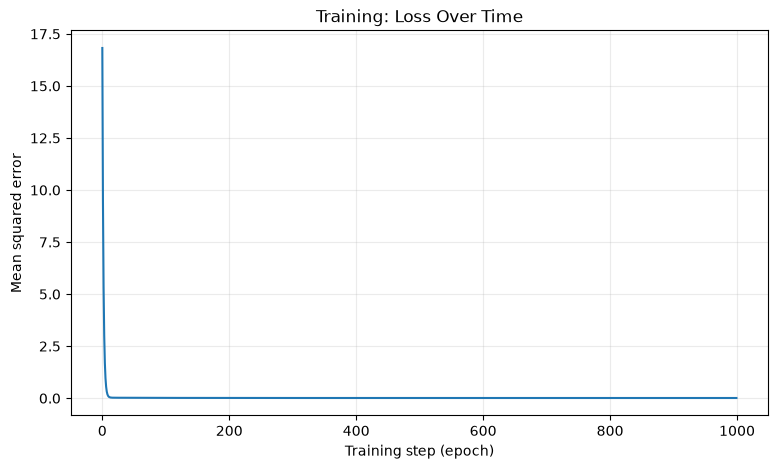

In [10]:
# Step 10: plot loss against training steps
plt.figure(figsize=(9, 5))
plt.plot(loss_history)
plt.title("Training: Loss Over Time")
plt.xlabel("Training step (epoch)")
plt.ylabel("Mean squared error")
plt.grid(alpha=0.25)
plt.savefig(OUTPUT_DIR / "training_loss.png", dpi=160, bbox_inches="tight")
plt.show()

## Step 11 — Inspect what the model learned

The model has learned two parameters: a weight and a bias. Remember that we scaled both the input and target:

\[
\text{price}_{100k} = w \times \text{area}_{100m^2} + b
\]

We can convert the learned parameters back into familiar units so that the relationship is easier to interpret:

\[
\text{price in USD} = (100000b) + (1000w) \times \text{area in m}^2
\]

The fitted values will not exactly match the rule used to generate the data because our examples contain random noise and are only a finite sample.

In [11]:
# Step 11: inspect the trained weight and bias
model.eval()
with torch.no_grad():
    learned_weight = model.linear.weight.item()
    learned_bias = model.linear.bias.item()

intercept_usd = learned_bias * 100_000
price_per_m2_usd = learned_weight * 1_000

print(f"Learned weight: {learned_weight:.4f}")
print(f"Learned bias:   {learned_bias:.4f}")
print()
print("Approximate learned relationship:")
print(
    f"price ≈ ${intercept_usd:,.0f} "
    f"+ ${price_per_m2_usd:,.0f} × area_m2"
)

Learned weight: 2.4308
Learned bias:   0.5846

Approximate learned relationship:
price ≈ $58,463 + $2,431 × area_m2


## Step 12 — Draw the model's learned relationship

The dots are the examples. The line is the relationship learned by the model. The purpose of the line is to summarize the pattern in the examples so that the model can make predictions for input values it has not been given before.

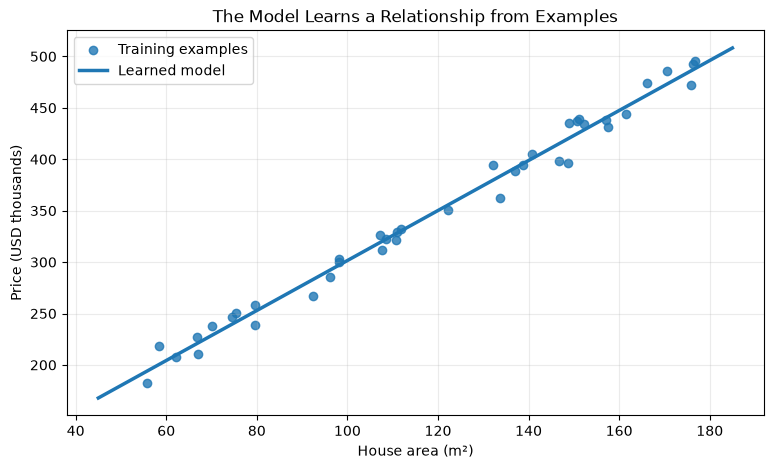

In [12]:
# Step 12: plot the training examples and the learned model line
area_line_m2 = torch.linspace(45, 185, steps=100, dtype=torch.float32).reshape(-1, 1)
area_line_scaled = area_line_m2 / 100.0

with torch.no_grad():
    price_line_usd = model(area_line_scaled).cpu().numpy().reshape(-1) * 100_000

plt.figure(figsize=(9, 5))
plt.scatter(houses["area_m2"], houses["price_usd"] / 1_000, label="Training examples", alpha=0.8)
plt.plot(area_line_m2.numpy().reshape(-1), price_line_usd / 1_000,
         label="Learned model", linewidth=2.5)
plt.title("The Model Learns a Relationship from Examples")
plt.xlabel("House area (m²)")
plt.ylabel("Price (USD thousands)")
plt.legend()
plt.grid(alpha=0.25)
plt.savefig(OUTPUT_DIR / "house_price_model.png", dpi=160, bbox_inches="tight")
plt.show()

## Step 13 — Use the model on a new house

Now we can ask the trained model to predict a price for a 120 m² house. This input is not a special case in the model. We simply convert it to the same units used during training and pass it through the model.

`torch.no_grad()` tells PyTorch that we are making a prediction rather than calculating gradients for another training update.

In [13]:
# Step 13: predict the price for a new 120 m² house
new_house_area_m2 = 120.0
new_house_input = torch.tensor([[new_house_area_m2 / 100.0]], dtype=torch.float32, device=DEVICE)

model.eval()
with torch.no_grad():
    predicted_price_100k = model(new_house_input).item()

predicted_price_usd = predicted_price_100k * 100_000

print(f"New house area: {new_house_area_m2:.0f} m²")
print(f"Predicted price: ${predicted_price_usd:,.0f}")
print("Remember: this is a prediction from synthetic teaching data, not a real valuation.")

New house area: 120 m²
Predicted price: $350,164
Remember: this is a prediction from synthetic teaching data, not a real valuation.


## Step 14 — Try several new inputs

A trained model can make predictions for many different inputs. Change the `new_areas_m2` values and run this cell again to experiment with the model.

In [14]:
# Step 14: try several house areas
new_areas_m2 = np.array([75, 100, 120, 150, 175], dtype=np.float32)
new_inputs = torch.tensor((new_areas_m2 / 100.0).reshape(-1, 1), dtype=torch.float32)

model.eval()
with torch.no_grad():
    new_predictions_usd = model(new_inputs).numpy().reshape(-1) * 100_000

prediction_table = pd.DataFrame({
    "area_m2": new_areas_m2.astype(int),
    "predicted_price_usd": np.round(new_predictions_usd).astype(int),
})
display(prediction_table)

,area_m2,predicted_price_usd
0,75,240776
1,100,301547
2,120,350164
3,150,423089
4,175,483860


## Step 15 — Save results for the video animations

The notebook is the **source of truth** for the example. The separate Manim project reads the CSV and JSON files created here, rather than training a different model or hard-coding a different prediction.

Run this cell after training. It saves the source examples, the loss history, and the learned parameters/prediction in `lesson_example/outputs/`.

In [15]:
# Step 15: export reproducible artifacts for the video-generation project
# OUTPUT_DIR was resolved in Step 0 and is shared by the notebook cells.
houses.to_csv(OUTPUT_DIR / "house_data.csv", index=False)
pd.DataFrame({"epoch": np.arange(1, len(loss_history) + 1), "loss": loss_history}).to_csv(
    OUTPUT_DIR / "training_loss.csv", index=False
)
prediction_table.to_csv(OUTPUT_DIR / "new_house_predictions.csv", index=False)

lesson_results = {
    "lesson": "3.1.1",
    "title": "What Is Machine Learning? From Data to Predictions",
    "data_description": "Synthetic house area and price examples for teaching only.",
    "random_seed_numpy": RANDOM_SEED,
    "random_seed_torch": TORCH_SEED,
    "number_of_examples": int(len(houses)),
    "model": {
        "type": "PyTorch nn.Linear(1, 1)",
        "weight": float(learned_weight),
        "bias": float(learned_bias),
        "learning_rate": float(learning_rate),
        "epochs": int(number_of_epochs),
        "initial_mse_loss": float(loss_history[0]),
        "final_mse_loss": float(loss_history[-1]),
    },
    "prediction": {
        "area_m2": float(new_house_area_m2),
        "price_usd": float(predicted_price_usd),
    },
    "units": {
        "model_input": "area in hundreds of square metres (area_m2 / 100)",
        "model_output": "price in hundreds of thousands of USD (price_usd / 100000)",
    },
}

with (OUTPUT_DIR / "lesson_results.json").open("w", encoding="utf-8") as file:
    json.dump(lesson_results, file, indent=2)

print(f"Saved lesson artifacts to: {OUTPUT_DIR.resolve()}")
for file_name in ["house_data.csv", "training_loss.csv", "new_house_predictions.csv", "lesson_results.json"]:
    print(" -", file_name)

Saved lesson artifacts to: D:\AI\VideoGeneration\Machine_Learning\lesson-3.1.1-what-is-machine-learning\lesson_example\outputs
 - house_data.csv
 - training_loss.csv
 - new_house_predictions.csv
 - lesson_results.json


## Step 16 — Recap and challenge

### What happened in this notebook?

1. We supplied examples containing a **feature** (house area) and a **target** (house price).
2. We built a model using `nn.Linear(1, 1)`.
3. The model made predictions using its current weight and bias.
4. The loss function measured the difference between predictions and example answers.
5. The training loop used gradients and SGD to update the model parameters.
6. We passed a new input through the trained model to obtain a prediction.

### Your challenge

Change the input in Step 13 from `120.0` to `90.0`, `140.0`, or another area. Run the prediction cell again.

Then change the number of training epochs in Step 9. Observe how the loss curve and learned parameters change.

### One important limitation

A model can learn patterns from the data it receives, including patterns that are incomplete or misleading. This notebook uses a clean, synthetic, one-feature problem to teach the mechanics. Real machine-learning projects require careful data preparation, reliable evaluation, and thoughtful interpretation. We will build those skills in the next lessons.